# Modul 2 - Transfer Learning dan Strategi Konvergensi

**Pokok Bahasan**
1. Persiapan Dataset
2. Arsitektur Model dengan Batch Normalization
3. Pre-Training dan Penyimpanan Model
4. Fine-Tuning dengan LR Scheduler
5. Visualisasi Kinerja dan Inferensi Data Baru

Modul ini mendemonstrasikan kekuatan Transfer Learning (menerapkan pengetahuan dari satu tugas ke tugas lain yang serupa). Pada modul akan dilakukan pelatihan model untuk mengenal gambar pakaian (Fashion MNIST), menyimpannya, lalu memanfaatkannya untuk mempercepat pembelajaran pengenalan angka (Digit MNIST).

Selain itu, pada modul juga akan diterapkan Batch Normalization (menyetabilkan distribusi input di dalam jaringan) dan Scheduler (mengurangi learning rate secara otomatis saat model mulai stuck pada proses pelatihan).

Modul ini akan menggunakan dataset computer vision bawaan dari torchvision FashionMNIST dan MNIST (Handwritten Digits).

## 1. Persiapan Data

In [35]:
# Library untuk penerapan deep learning berbasis pytorch
import torch
import torch.nn as nn
import torch.optim as optim
# Library yang digunakan untuk pengolahan citra (computer vision) hingga augmentasi
import torchvision
import torchvision.transforms as transforms
# Library untuk visualisasi data
import matplotlib.pyplot as plt

In [36]:
# Transformasi: Mengubah citra PIL menjadi Tensor dan meratakan nilai piksel (Normalisasi dasar 0-1)
transform = transforms.Compose([transforms.ToTensor()])

# Memuat Dataset Fashion MNIST (Pakaian) untuk PRE-TRAINING
trainset_fashion = torchvision.datasets.FashionMNIST(root='./data', train=True,
                                                     download=True, transform=transform)
trainloader_fashion = torch.utils.data.DataLoader(trainset_fashion, batch_size=256,
                                                  shuffle=True)

# Memuat Dataset MNIST (Angka Tulis Tangan) untuk FINE-TUNING
trainset_digit = torchvision.datasets.MNIST(root='./data', train=True, download=True,
                                            transform=transform)
testset_digit = torchvision.datasets.MNIST(root='./data', train=False, download=True,
                                           transform=transform)
trainloader_digit = torch.utils.data.DataLoader(trainset_digit, batch_size=256, shuffle=True)
testloader_digit = torch.utils.data.DataLoader(testset_digit, batch_size=256, shuffle=False)

print("Dataset berhasil dimuat!")

Dataset berhasil dimuat!


## 2. Arsitektur Model dengan Batch Normalization

Saat forward signal melewati banyak lapisan, variansnya bisa meledak atau menyusut. Batch Normalization menormalkan output dari setiap hidden layer di dalam mini batch, sehingga proses konvergensi (pencapaian minimum loss) terjadi secara jauh lebih stabil dan cepat.

In [37]:
class VisionMLP(nn.Module):
  def __init__(self):
    super(VisionMLP, self).__init__()
    # Input citra grayscale 28x28 piksel = 784 fitur 1D
    self.flatten = nn.Flatten()
    self.fc1 = nn.Linear(784, 256)
    self.bn1 = nn.BatchNorm1d(256) # Normalisasi Batch pada output layer 1
    self.fc2 = nn.Linear(256, 128)
    self.bn2 = nn.BatchNorm1d(128) # Normalisasi Batch pada output layer 2
    self.fc3 = nn.Linear(128, 10)  # 10 Kelas output
    self.relu = nn.ReLU()

  def forward(self, x):
    x = self.flatten(x)
    # Urutan umum: Linear -> Batch Norm -> Activation
    x = self.relu(self.bn1(self.fc1(x)))
    x = self.relu(self.bn2(self.fc2(x)))
    # Output logits
    x = self.fc3(x)
    return x

In [38]:
# Inisialisasi model dan kirim ke GPU jika tersedia
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_vision = VisionMLP().to(device)
print(f"Model dialokasikan pada: {device}")

Model dialokasikan pada: cpu


## 3. Pre-Training dan Penyimpanan Model

Proses dilanjutkan dengan pelatihan model pada tugas pertama (Fashion MNIST) untuk mempelajari deteksi tepi dan kurva dasar.

In [39]:
# Simpan bobot (pengetahuan) model
torch.save(model_vision.state_dict(), 'pretrained_fashion.pth')
print("Model berhasil disimpan ke 'pretrained_fashion.pth'")

Model berhasil disimpan ke 'pretrained_fashion.pth'


## 4. Fine-Tuning dengan LR Scheduler

Pada proses sebelumnya telah dibuat model yang pintar mengenali pakaian, lalu "redirect" kepintarannya untuk mengenali angka.

Pada tahap ini akan digunakan `ReduceLROnPlateau` Scheduler. Fitur ini memantau nilai Loss. Jika Loss berhenti menurun selama beberapa epoch (terjebak di dataran/plateau), Scheduler akan otomatis memperkecil Learning Rate agar algoritma melangkah lebih hati-hati (tidak melompati titik minimum global).

In [44]:
# Memuat kembali bobot pre-trained
transfer_model = VisionMLP().to(device)
transfer_model.load_state_dict(torch.load('pretrained_fashion.pth'))

# TRANSFER LEARNING:
# Mengganti (re-inisialisasi) lapisan terakhir (Head) untuk tugas spesifik yang baru
transfer_model.fc3 = nn.Linear(128, 15).to(device)
print(transfer_model)

VisionMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (bn1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc3): Linear(in_features=128, out_features=15, bias=True)
  (relu): ReLU()
)


In [45]:
# Inisialisasi Optimizer dan Scheduler. Pada scheduler, Jika nilai validasi loss
# tidak turun dalam 2 epoch (patience=2), kurangi LR sebanyak faktor 0.1
optimizer_ft = optim.Adam(transfer_model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer_ft, mode='min',
                                                 factor=0.1, patience=2)

# Inisialisasi loss function, num of epoch, dan beberapa list
# untuk mencatat proses pelatihan
criterion_ft = nn.CrossEntropyLoss()
num_epochs_ft = 15
ft_train_losses, ft_test_losses = [], []
ft_test_accs = []

print("--- Fine-Tuning pada Digit MNIST ---")
for epoch in range(num_epochs_ft):
  # Tahap Training
  transfer_model.train()
  train_loss = 0
  for images, labels in trainloader_digit:
    images, labels = images.to(device), labels.to(device)
    optimizer_ft.zero_grad() # Mengosongkan gradien sebelum backward pass
    loss = criterion_ft(transfer_model(images), labels) # Menghitung loss dalam satu batch
    loss.backward()
    optimizer_ft.step() # Memperbarui bobot model berdasarkan gradien
    optimizer_ft.zero_grad() # Mengosongkan gradien
    train_loss += loss.item() 
  avg_train_loss = train_loss / len(trainloader_digit)

  # Tahap Evaluasi
  transfer_model.eval()
  test_loss, correct, total = 0, 0, 0
  with torch.no_grad():
    for images, labels in testloader_digit:
      images, labels = images.to(device), labels.to(device)
      outputs = transfer_model(images)
      loss = criterion_ft(outputs, labels)
      test_loss += loss.item()
      # Mengambil prediksi probabilitas tertinggi (argmax)
      _, predicted = torch.max(outputs.data, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()
  avg_test_loss = test_loss / len(testloader_digit)
  accuracy = correct / total

  ft_train_losses.append(avg_train_loss)
  ft_test_losses.append(avg_test_loss)
  ft_test_accs.append(accuracy)

  # Update Scheduler berdasarkan Validation Loss
  scheduler.step(avg_test_loss)

  print(f"Epoch {epoch+1:2d}")
  print(f"Train Loss: {avg_train_loss:.4f} | Test Loss: {avg_test_loss:.4f}")
  print(f"Test Acc: {accuracy*100:.2f}%")

--- Fine-Tuning pada Digit MNIST ---
Epoch  1
Train Loss: 0.2955 | Test Loss: 0.1203
Test Acc: 96.78%
Epoch  2
Train Loss: 0.0852 | Test Loss: 0.0793
Test Acc: 97.46%
Epoch  3
Train Loss: 0.0510 | Test Loss: 0.0698
Test Acc: 97.65%
Epoch  4
Train Loss: 0.0350 | Test Loss: 0.0635
Test Acc: 97.91%
Epoch  5
Train Loss: 0.0253 | Test Loss: 0.0635
Test Acc: 97.95%
Epoch  6
Train Loss: 0.0189 | Test Loss: 0.0672
Test Acc: 97.83%
Epoch  7
Train Loss: 0.0140 | Test Loss: 0.0702
Test Acc: 97.81%
Epoch  8
Train Loss: 0.0076 | Test Loss: 0.0535
Test Acc: 98.32%
Epoch  9
Train Loss: 0.0042 | Test Loss: 0.0520
Test Acc: 98.43%
Epoch 10
Train Loss: 0.0033 | Test Loss: 0.0513
Test Acc: 98.43%
Epoch 11
Train Loss: 0.0029 | Test Loss: 0.0515
Test Acc: 98.45%
Epoch 12
Train Loss: 0.0025 | Test Loss: 0.0508
Test Acc: 98.52%
Epoch 13
Train Loss: 0.0022 | Test Loss: 0.0510
Test Acc: 98.51%
Epoch 14
Train Loss: 0.0022 | Test Loss: 0.0521
Test Acc: 98.50%
Epoch 15
Train Loss: 0.0019 | Test Loss: 0.0516
Test 

## 5. Visualisasi Kinerja dan Inferensi Data Baru

Pada tahap akhir, akan dilakukan analisis bagaimana Scheduler dan Batch Normalization bekerja secara stabil, lalu selanjutnya diuji prediksi model secara visual pada gambar tulisan tangan.

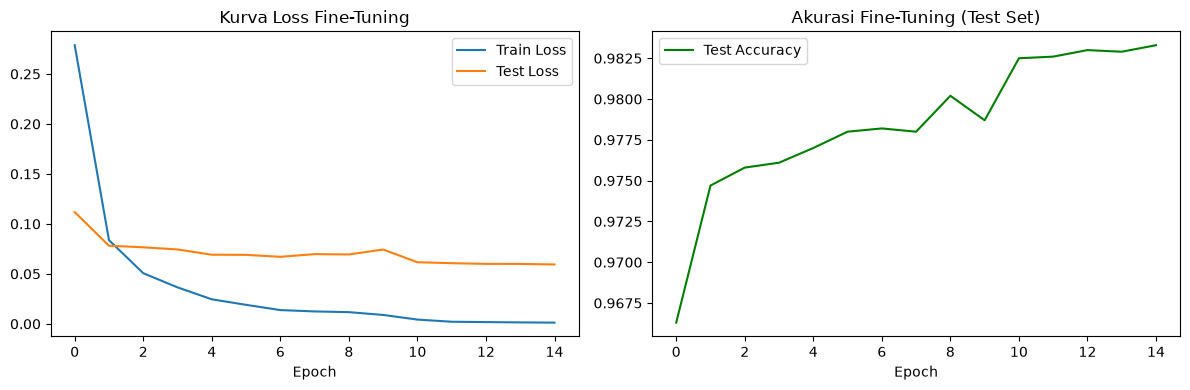

In [42]:
# Plotting Loss & Accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(ft_train_losses, label='Train Loss')
plt.plot(ft_test_losses, label='Test Loss')
plt.title('Kurva Loss Fine-Tuning')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(ft_test_accs, color='green', label='Test Accuracy')
plt.title('Akurasi Fine-Tuning (Test Set)')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

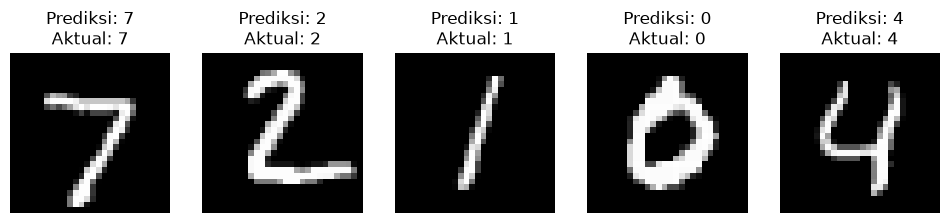

In [43]:
# Contoh Inferensi (Pengujian pada data gambar nyata)
dataiter = iter(testloader_digit)
images, labels = next(dataiter)

transfer_model.eval()
with torch.no_grad():
  outputs = transfer_model(images.to(device))
  _, preds = torch.max(outputs, 1)

# Menampilkan 5 gambar pertama beserta tebakan modelnya
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
  ax = axes[i]
  # squeeze untuk membuang dimensi channel (1, 28, 28) -> (28, 28)
  ax.imshow(images[i].squeeze(), cmap='gray') 
  ax.set_title(f"Prediksi: {preds[i].item()}\nAktual: {labels[i].item()}")
  ax.axis('off')
plt.show()